# pr_classic3 -- canal 2, OPENING THE AGGREGATE

Companion to `canal2_uncertainty_vs_error_classic.ipynb`, which gives **one mean per (axis, case) with its interval over donors**. A mean does not say whether it covers a homogeneous signal or a few isolated groups, nor where the signal comes from. This notebook recomputes nothing: it opens the same files group by group.

Five openings, from the cheapest to the most expensive:

1. **The distribution behind the mean** -- the per-group values, not only their mean.
2. **The gene axis opened gene by gene** -- a few markers against the whole panel.
3. **The mean as a confounder, seen directly** -- the distribution of `r_um`, the `u`↔`mu` coupling WITHIN the group, which is the whole reason the control exists.
4. **The three cases compared PER GROUP** -- this is the question the three cases exist to make possible: do they rank the same groups?
5. **The spot axis resolved by tissue type** -- the only section that reads the preprocessed adata.

Every figure has its **printed twin**: no value exists only as pixels.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))

# ════════════════════════════ SETTINGS ════════════════════════════════
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
PREPROC_ID  = "v5"           # used ONLY by section 5 (tissue types)
CANAL2      = "canal2_uncertainty"
LAMBDA_KEEP = 0.0
MODELS      = ["homoscedastic", "heteroscedastic", "spot_homoscedastic", "poisson_cp",
               "negativebinomial_hetero_noanchor_cp", "negativebinomial_spotdisp_cp",
               "negativebinomial_genedisp_cp"]
RAW_MODELS  = ["poisson_raw", "negativebinomial_hetero_noanchor_raw"]
# The error case shown by sections 2, 3 and 5. All three stay available everywhere ;
# section 4 compares them explicitly.
MAIN_CASE   = "lin_pos"
FIGDIR      = PROJ / "results" / "_analysis" / "figures"   # convention canal 1
# ═════════════════════════════════════════════════════════════════════════════

N_PLUS_MIN = 60
CONVENTION = "v3_native_scale"
CASES = ["lin_all", "lin_pos", "log_pos"]
CASE_LABELS = {"lin_all": "|y - mu|  all entries (zeros included)",
               "lin_pos": "|y - mu|  y > 0",
               "log_pos": "|log y - log mu|  y > 0"}
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
AXES = ["gene", "spot"]

MODEL_COLORS = {
    "homoscedastic":                        "#1f77b4",
    "heteroscedastic":                      "#ff7f0e",
    "spot_homoscedastic":                   "#2ca02c",
    "poisson_cp":                           "#d62728",
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",
    "negativebinomial_spotdisp_cp":         "#e377c2",
    "negativebinomial_genedisp_cp":         "#17becf",
    "poisson_raw":                          "#d62728",
    "negativebinomial_hetero_noanchor_raw": "#9467bd",
}
MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
    "negativebinomial_spotdisp_cp":         "NB, dispersion per spot",
    "negativebinomial_genedisp_cp":         "NB, dispersion per gene",
    "poisson_raw":                          "Poisson (raw counts)",
    "negativebinomial_hetero_noanchor_raw": "Negative binomial (raw counts)",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

# Markers per cohort, defined OUTSIDE this run (literature, not a selection made on these
# predictions).
MARKERS = {
    "10x_TuPro":   ["TYR", "PMEL", "S100B", "MLPH", "SOX10"],        # lineage melanocytic
    "TLS":         ["LTB", "MS4A1", "CXCL13", "CCL19", "CD19"],      # structure lymphoid / lymphocyte B
    "LUNG_CANCER": ["SPP1", "TREM2", "APOE", "APOC1", "FABP5"],      # TAM / metabolism lipid
}

# Canonical tissue -> color map. A tissue keeps
# ONE color across every figure of the paper, and the two cohorts share the semantic alignment
# (red = tumor, green = healthy, orange = altered / infiltrated tissue, beige = structurally neutral).
TISSUE_COLORS = {
    "Tumor": "#D62728", "Blood and necrosis": "#F08A24", "Stroma": "#D9C7A3",
    "Normal lymphoid tissue": "#3FA34D", "Pigment": "#26415F",
    "TUM": "#D62728", "NOR": "#3FA34D", "INFL": "#F08A24", "LN": "#D9C7A3", "TLS": "#3B6BC4",
}

DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())

def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}

def canal2_runs(ds, models):
    base = RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS
    out = []
    if not base.is_dir():
        return out
    for model_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        if model_dir.name not in models:
            continue
        for leaf in [model_dir] + sorted(model_dir.glob("lambda_*")):
            lam = leaf.name if leaf.name.startswith("lambda_") else None
            if lam is not None and LAMBDA_KEEP is not None:
                if not np.isclose(float(lam[len("lambda_"):]), LAMBDA_KEEP):
                    continue
            if (leaf / CANAL2 / "summary.json").is_file():
                out.append(dict(dataset=ds, model_type=model_dir.name, dir=leaf / CANAL2))
    return out

RUNS, stale = [], []
for ds in DATASETS:
    for r in canal2_runs(ds, MODELS + RAW_MODELS):
        s = json.loads((r["dir"] / "summary.json").read_text())
        if s.get("not_applicable"):
            continue
        if s.get("canal2_convention") != CONVENTION:
            stale.append((r["dataset"], r["model_type"], s.get("canal2_convention")))
            continue
        r["summary"] = s
        RUNS.append(r)

PAIR = {(r["dataset"], r["model_type"]): pd.read_parquet(r["dir"] / "pair_partial.parquet")
        for r in RUNS if (r["dir"] / "pair_partial.parquet").is_file()}
SPOT = {(r["dataset"], r["model_type"]): pd.read_parquet(r["dir"] / "spot_partial.parquet")
        for r in RUNS if (r["dir"] / "spot_partial.parquet").is_file()}
SUMM = {(r["dataset"], r["model_type"]): r["summary"] for r in RUNS}
ALL_MODELS = MODELS + RAW_MODELS
from matplotlib.lines import Line2D

CASE_FIG = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
            "lin_pos": "|y - mu|, detected entries only (y > 0)",
            "log_pos": "|log y - log mu|, detected entries only (y > 0)"}

def fig_show(fig, stem, title, caption):
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")

FIGDIR.mkdir(parents=True, exist_ok=True)


def groups(ds, m, axis, case, stat="r_partial"):
    """The PER-GROUP values of an (axis, case, statistic), filtered as the script filters them.

    Returns the full frame, not only the column : the sections below need the group key
    (gene / spot / slide) to open the mean along another dimension."""
    frame = (PAIR if axis == "gene" else SPOT).get((ds, m))
    col, ncol = f"{stat}_{case}", N_COL[case]
    if frame is None or col not in frame.columns or ncol not in frame.columns:
        return None
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    return None if d.empty else d


print(f"canal2 = {CANAL2!r}   main case = {MAIN_CASE!r} ({CASE_LABELS[MAIN_CASE]})")
for ds in DATASETS:
    got = sorted(m for (d, m) in SUMM if d == ds)
    print(f"  {ds:<12s} {len(got):>2d} runs   "
          f"pair_partial {sum(1 for k in PAIR if k[0] == ds)}   "
          f"spot_partial {sum(1 for k in SPOT if k[0] == ds)}")
if stale:
    print(f"\n(!) {len(stale)} run(s) NOT conforming to canal2_convention={CONVENTION!r} -- DROPPED: {stale}")

canal2 = 'canal2_uncertainty'   main case = 'lin_pos' (|y - mu|  y > 0)
  10x_TuPro     9 runs   pair_partial 9   spot_partial 9
  TLS           9 runs   pair_partial 9   spot_partial 9
  LUNG_CANCER   9 runs   pair_partial 9   spot_partial 9


## 1. The distribution behind the mean

A section's mean does not say whether the signal is homogeneous. A small mean can cover a majority of groups at zero, or strongly positive groups canceled by strongly negative ones -- two situations that do not call for the same conclusion.

Three numbers are enough to decide: the **median** (against the mean), the **quartiles** (the spread), and the **share of positive groups** (the symmetry). If the median and the mean agree and the positive share is far from 50 %, the signal is real and homogeneous; if the positive share is close to 50 % with wide quartiles, the mean is a difference between two opposed populations.

Reading reminder: `n_groups` is the number of groups KEPT (`n ≥ 60`), not the number of groups present. It is also the real weight behind the mean.

THE PER-GROUP DISTRIBUTION BEHIND EACH MEAN
  mean ~ median and positive share far from 50%  ->  homogeneous signal
  small mean, wide quartiles, positive share ~ 50%  ->  a difference between two
  opposed populations, not an overall effect
  weights by n and goes through the donors. The two cannot coincide exactly.

[lin_all | axis gene | CONTROLLED value]
  cohort                 head                                       n groups      mean    median      Q25      Q75   % > 0
  Tumor Profiler         Gaussian heteroscedastic                     53,998   +0.0543   +0.0468   -0.006   +0.117   72.3%
  Tumor Profiler         Gaussian spot-homoscedastic                  53,999   +0.0554   +0.0548   -0.007   +0.123   72.7%
  Tumor Profiler         Negative binomial                            53,975   +0.0265   +0.0211   -0.016   +0.081   63.9%
  Tumor Profiler         NB, dispersion per spot                      53,975   +0.0287   +0.0181   -0.011   +0.079   63.4%
  Tumor Profiler        

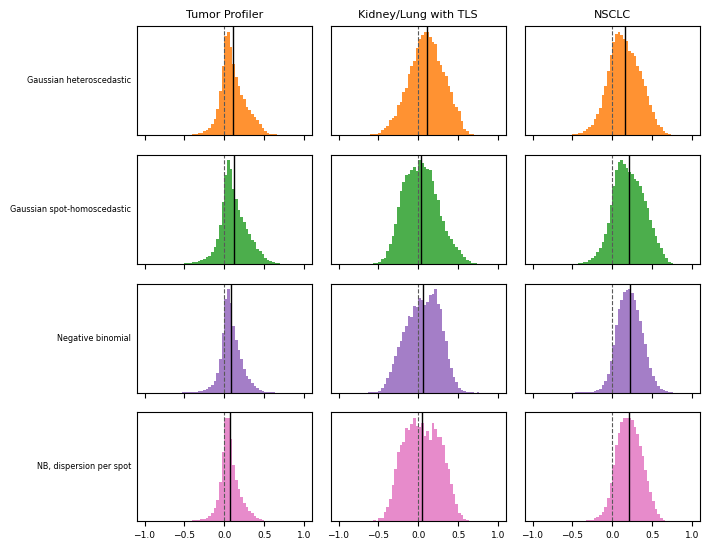

## FIGURE  fig_canal2_open_dist_gene_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   Distribution of the per-group controlled correlation on the gene axis
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One histogram per predictive head and cohort, over the groups that pass the
## CAPTION inclusion floor. Solid black line: the unweighted mean over groups. Dashed line:
## CAPTION zero. A mean close to the median with a positive share far from 50 % indicates a
## CAPTION homogeneous effect; a mean near zero with wide quartiles indicates a difference
## CAPTION between two opposed populations rather than an overall effect.
## CAPTION The counts behind these histograms are printed in the table above.


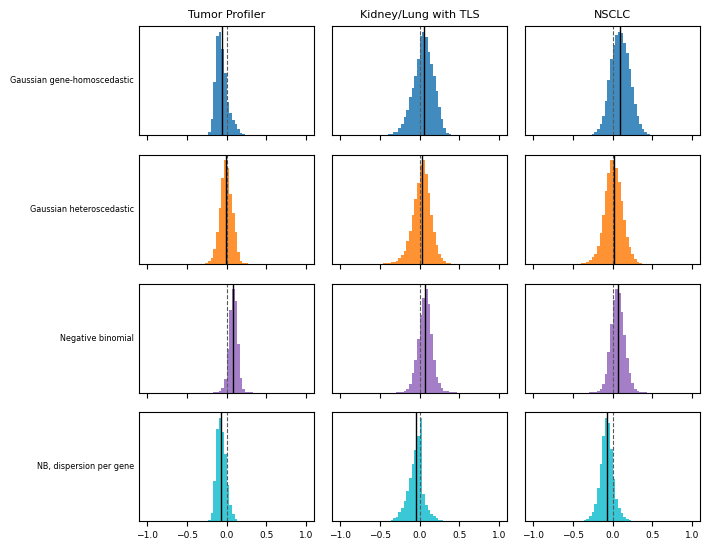

## FIGURE  fig_canal2_open_dist_spot_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   Distribution of the per-group controlled correlation on the spot axis
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One histogram per predictive head and cohort, over the groups that pass the
## CAPTION inclusion floor. Solid black line: the unweighted mean over groups. Dashed line:
## CAPTION zero. A mean close to the median with a positive share far from 50 % indicates a
## CAPTION homogeneous effect; a mean near zero with wide quartiles indicates a difference
## CAPTION between two opposed populations rather than an overall effect.
## CAPTION The counts behind these histograms are printed in the table above.

(the numbers in these histograms are exactly the table above, row 'lin_pos | axis ... | CONTROLLED value')


In [2]:
rows = []
for (ds, m) in SUMM:
    for axis in AXES:
        for case in CASES:
            for stat, tag in (("r_uD", "uncontrolled"), ("r_partial", "controlled")):
                d = groups(ds, m, axis, case, stat)
                if d is None:
                    continue
                v = d[f"{stat}_{case}"].to_numpy()
                rows.append(dict(dataset=ds, model=m, axis=axis, case=case, stat=tag,
                                 n=len(v), mean=float(np.mean(v)), median=float(np.median(v)),
                                 q25=float(np.percentile(v, 25)), q75=float(np.percentile(v, 75)),
                                 pct_pos=float(100 * np.mean(v > 0))))
DIST = pd.DataFrame(rows)

print("=" * 130)
print("THE PER-GROUP DISTRIBUTION BEHIND EACH MEAN")
print("  mean ~ median and positive share far from 50%  ->  homogeneous signal")
print("  small mean, wide quartiles, positive share ~ 50%  ->  a difference between two")
print("  opposed populations, not an overall effect")
print("  WARNING : UNWEIGHTED mean over groups here ; section 3 of the main notebook")
print("  weights by n and goes through the donors. The two cannot coincide exactly.")
print("=" * 130)
for case in CASES:
    for axis in AXES:
        sub = DIST[(DIST["case"] == case) & (DIST["axis"] == axis) & (DIST["stat"] == "controlled")]
        if sub.empty:
            continue
        print(f"\n[{case} | axis {axis} | CONTROLLED value]")
        print(f"  {'cohort':<22s} {'head':<40s} {'n groups':>10s} {'mean':>9s} "
              f"{'median':>9s} {'Q25':>8s} {'Q75':>8s} {'% > 0':>7s}")
        for ds in DATASETS:
            for m in ALL_MODELS:
                r = sub[(sub["dataset"] == ds) & (sub["model"] == m)]
                if r.empty:
                    continue
                r = r.iloc[0]
                print(f"  {DATASET_LABELS.get(ds, ds):<22s} {MODEL_LABELS.get(m, m):<40s} "
                      f"{r['n']:>10,} {r['mean']:>+9.4f} {r['median']:>+9.4f} "
                      f"{r['q25']:>+8.3f} {r['q75']:>+8.3f} {r['pct_pos']:>6.1f}%")

# ── the figure : one histogram per head, for the main case, both axes ──────────────────────────
for axis in AXES:
    live = [m for m in MODELS if any(groups(ds, m, axis, MAIN_CASE) is not None for ds in DATASETS)]
    if not live:
        continue
    fig, axarr = plt.subplots(len(live), len(DATASETS),
                              figsize=(2.4 * len(DATASETS), 1.4 * len(live)),
                              sharex=True, squeeze=False)
    for i, m in enumerate(live):
        for j, ds in enumerate(DATASETS):
            ax = axarr[i, j]
            d = groups(ds, m, axis, MAIN_CASE)
            if d is not None:
                v = d[f"r_partial_{MAIN_CASE}"].to_numpy()
                ax.hist(v, bins=60, range=(-1, 1), color=MODEL_COLORS.get(m, "0.4"), alpha=0.85)
                ax.axvline(0.0, color="0.35", lw=0.8, ls="--")
                ax.axvline(float(np.mean(v)), color="k", lw=1.0)
            ax.set_yticks([])
            ax.tick_params(axis="x", labelsize=6.5)
            if i == 0:
                ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
            if j == 0:
                ax.set_ylabel(MODEL_LABELS.get(m, m), fontsize=5.8, rotation=0,
                              ha="right", va="center")
    fig.tight_layout()
    fig_show(fig, FIGDIR / f"fig_canal2_open_dist_{axis}_{MAIN_CASE}_{RUN_ID}_{CANAL2}",
             f"Distribution of the per-group controlled correlation on the {axis} axis",
             [f"Error definition: {CASE_FIG[MAIN_CASE]}.",
              "One histogram per predictive head and cohort, over the groups that pass the",
              "inclusion floor. Solid black line: the unweighted mean over groups. Dashed line:",
              "zero. A mean close to the median with a positive share far from 50 % indicates a",
              "homogeneous effect; a mean near zero with wide quartiles indicates a difference",
              "between two opposed populations rather than an overall effect.",
              "The counts behind these histograms are printed in the table above."])
print("\n(the numbers in these histograms are exactly the table above, row "
      f"'{MAIN_CASE} | axis ... | CONTROLLED value')")

## 2. The gene axis, opened gene by gene

A group on the gene axis is a (gene, slide): the correlation asks whether the predicted uncertainty ranks the error **across the spots** where that gene is detected. The section 3 mean folds all the genes together; here we look at a few named genes next to the whole panel.

The markers are defined **outside this run** (literature panels), so they are not genes picked because they gave a good number.

Each cell averages the cohort's slides **weighted by n**, the weighting used in the section 3 aggregation. Each head appears twice, naive then controlled: the difference between two consecutive rows IS the effect of the confounder.

GENE AXIS OPENED GENE BY GENE -- case lin_pos (|y - mu|  y > 0)
  columns : the cohort's markers, then ALL genes. 'mute' = no valid group
  (gene absent from the panel, never 60 detected spots, or head degenerate on this axis).

--- Tumor Profiler ---
  head                                                      TYR      PMEL     S100B      MLPH     SOX10       ALL
  Gaussian heteroscedastic                 uncontrolled   -0.1219   -0.0864   +0.0985   -0.1572   +0.2491   +0.0884
  Gaussian heteroscedastic                 controlled     -0.0467   -0.0898   +0.0557   -0.0094   +0.0247   +0.0980
  Gaussian spot-homoscedastic              uncontrolled   -0.0796   -0.0291   +0.0988   -0.1675   +0.2496   +0.1270
  Gaussian spot-homoscedastic              controlled     -0.0280   -0.0439   +0.0817   -0.0496   +0.0393   +0.1089
  Poisson                                  uncontrolled   +0.4034   +0.3101   +0.5252   +0.4819   +0.0297   -0.0311
  Negative binomial                        uncontrolle

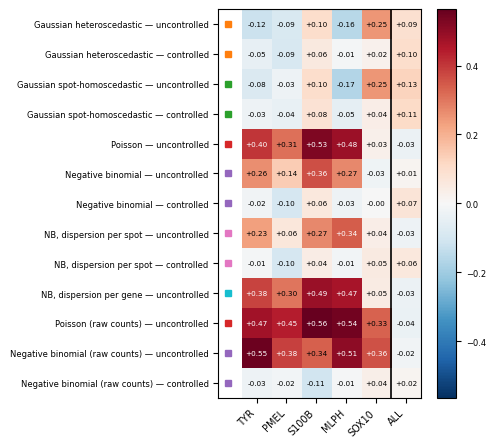

## FIGURE  fig_canal2_open_genes_10x_TuPro_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   Tumor Profiler: the association between the predicted uncertainty and the prediction error, gene by gene, for every head
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One group per gene and slide: the correlation asks whether the predicted
## CAPTION uncertainty ranks the error across the spots where that gene is detected. Each
## CAPTION cell averages every slide of the cohort, weighted by the number of detected
## CAPTION spots, the weighting used in the aggregation of the section.
## CAPTION The first columns are marker genes, defined outside this run; the last one, set
## CAPTION apart by a vertical rule, summarizes all genes of the cohort.
## CAPTION Each head appears twice, without any control and as the partial correlation
## CAPTION controlling for the predicted mean, so the difference between two consecutive
## CAPTION rows is the effect of the co

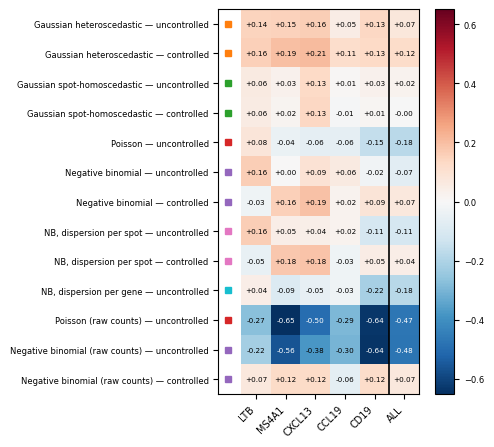

## FIGURE  fig_canal2_open_genes_TLS_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   Kidney/Lung with TLS: the association between the predicted uncertainty and the prediction error, gene by gene, for every head
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One group per gene and slide: the correlation asks whether the predicted
## CAPTION uncertainty ranks the error across the spots where that gene is detected. Each
## CAPTION cell averages every slide of the cohort, weighted by the number of detected
## CAPTION spots, the weighting used in the aggregation of the section.
## CAPTION The first columns are marker genes, defined outside this run; the last one, set
## CAPTION apart by a vertical rule, summarizes all genes of the cohort.
## CAPTION Each head appears twice, without any control and as the partial correlation
## CAPTION controlling for the predicted mean, so the difference between two consecutive
## CAPTION rows is the effect of the co

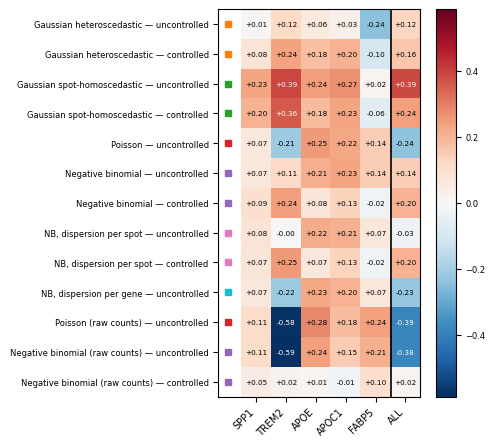

## FIGURE  fig_canal2_open_genes_LUNG_CANCER_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   NSCLC: the association between the predicted uncertainty and the prediction error, gene by gene, for every head
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One group per gene and slide: the correlation asks whether the predicted
## CAPTION uncertainty ranks the error across the spots where that gene is detected. Each
## CAPTION cell averages every slide of the cohort, weighted by the number of detected
## CAPTION spots, the weighting used in the aggregation of the section.
## CAPTION The first columns are marker genes, defined outside this run; the last one, set
## CAPTION apart by a vertical rule, summarizes all genes of the cohort.
## CAPTION Each head appears twice, without any control and as the partial correlation
## CAPTION controlling for the predicted mean, so the difference between two consecutive
## CAPTION rows is the effect of the confounde

In [3]:
def gene_value(ds, m, case, stat, gene=None):
    """Value for ONE gene (n-weighted mean over its slides), or for ALL genes
    (same weighting, then plain mean over the genes -- the script's cascade)."""
    d = groups(ds, m, "gene", case, stat)
    if d is None:
        return np.nan
    col, ncol = f"{stat}_{case}", N_COL[case]
    if gene is not None:
        d = d[d["gene"] == gene]
        if d.empty:
            return np.nan
        return float((d[col] * d[ncol]).sum() / d[ncol].sum())
    g = pd.DataFrame({"gene": d["gene"].to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby("gene", as_index=False).sum()
    return float((g["w"] / g["n"]).mean())


print("=" * 130)
print(f"GENE AXIS OPENED GENE BY GENE -- case {MAIN_CASE} ({CASE_LABELS[MAIN_CASE]})")
print("  columns : the cohort's markers, then ALL genes. 'mute' = no valid group")
print("  (gene absent from the panel, never 60 detected spots, or head degenerate on this axis).")
print("=" * 130)
HEAT = {}
for ds in DATASETS:
    mk = MARKERS.get(ds, [])
    cols = mk + ["ALL"]
    print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
    print(f"  {'head':<40s} {'':<10s} " + " ".join(f"{c:>9s}" for c in cols))
    rows = []
    for m in ALL_MODELS:
        for stat, tag in (("r_uD", "uncontrolled"), ("r_partial", "controlled")):
            vals = [gene_value(ds, m, MAIN_CASE, stat, g) for g in mk] \
                   + [gene_value(ds, m, MAIN_CASE, stat)]
            if all(not np.isfinite(v) for v in vals):
                continue
            cells = " ".join((f"{v:>+9.4f}" if np.isfinite(v) else f"{'mute':>9s}") for v in vals)
            print(f"  {MODEL_LABELS.get(m, m):<40s} {tag:<12s} {cells}")
            rows.append(dict(model=m, stat=tag, **dict(zip(cols, vals))))
    HEAT[ds] = pd.DataFrame(rows)

# ── the figure : one heatmap per cohort ────────────────────────────────────────────────────────
for ds in DATASETS:
    H = HEAT.get(ds)
    if H is None or H.empty:
        continue
    cols = MARKERS.get(ds, []) + ["ALL"]
    M = H[cols].to_numpy(dtype=float)
    vmax = float(np.nanmax(np.abs(M))) if np.isfinite(M).any() else 1.0
    fig, ax = plt.subplots(figsize=(0.85 * len(cols) + 3.4, 0.26 * len(H) + 1.2))
    # aspect equal : it is the CELLS that must be square, not the panel. Forcing the panel
    # square over 6 columns and 14 rows would squash the cells into thin rectangles.
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="equal")
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, fontsize=7, rotation=45, ha="right")
    ax.set_yticks(range(len(H)))
    ax.set_yticklabels([f"{MODEL_LABELS.get(r['model'], r['model'])} — {r['stat']}"
                        for _, r in H.iterrows()], fontsize=6)
    ax.axvline(len(cols) - 1.5, color="k", lw=1.2)      # separates the markers from the ALL column
    # Color dot per model, to the left of its label : the same color as in every other
    # figure, so a head is recognizable from one figure to the next.
    for i, (_, r) in enumerate(H.iterrows()):
        ax.plot([-0.95], [i], marker="s", ms=4.5, clip_on=False, zorder=5,
                color=MODEL_COLORS.get(r["model"], "0.5"))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                ax.text(j, i, f"{M[i, j]:+.2f}", ha="center", va="center", fontsize=5.2,
                        color="white" if abs(M[i, j]) > 0.6 * vmax else "black")
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).ax.tick_params(labelsize=6)
    fig.tight_layout()
    fig_show(fig, FIGDIR / f"fig_canal2_open_genes_{ds}_{MAIN_CASE}_{RUN_ID}_{CANAL2}",
             f"{DATASET_LABELS.get(ds, ds)}: the association between the predicted uncertainty "
             f"and the prediction error, gene by gene, for every head",
             [f"Error definition: {CASE_FIG[MAIN_CASE]}.",
              "One group per gene and slide: the correlation asks whether the predicted",
              "uncertainty ranks the error across the spots where that gene is detected. Each",
              "cell averages every slide of the cohort, weighted by the number of detected",
              "spots, the weighting used in the aggregation of the section.",
              "The first columns are marker genes, defined outside this run; the last one, set",
              "apart by a vertical rule, summarizes all genes of the cohort.",
              "Each head appears twice, without any control and as the partial correlation",
              "controlling for the predicted mean, so the difference between two consecutive",
              "rows is the effect of the confounder. The square left of each label carries that",
              "head's color, the same one it has in every other figure.",
              f"One color scale, plus or minus {vmax:.3f}."])

## 3. The mean as a confounder, seen directly

`r_um = Spearman(u, mu)` WITHIN the group is the quantity the control exists to remove. It is written per group in the parquets, so its distribution is readable without recomputing anything, and it alone explains the structure of the results:

- `r_um` close to **±1** → the head has no degree of freedom independent of `mu` on this axis: the partial is undefined, the head is **mute**. That is not missing data.
- `r_um` close to **0** → the uncertainty is nearly orthogonal to the mean within the group, and naive ≈ controlled.
- in between → the naive/controlled gap is proportional to `r_um`, and that is exactly what the second plot shows.

⚠️ `r_um` is computed on the case's population, so `r_um_lin_all` ≠ `r_um_lin_pos` while `r_um_lin_pos` = `r_um_log_pos` exactly (same population, and `r_um` does not depend on the error definition). This equality is checked at the end of the cell: a free consistency check on the file.

r_um PER GROUP -- the uncertainty <-> predicted mean coupling, WITHIN the group
  |r_um| ~ 1 on almost every group  ->  head mute on this axis, by construction

[axis gene | case lin_pos]
  cohort                 head                                             n    median      Q25      Q75  % |r_um|>0.99
  Tumor Profiler         Gaussian heteroscedastic                    47,228   +0.3067   -0.348   +0.753           0.0%
  Tumor Profiler         Gaussian spot-homoscedastic                 47,228   -0.1203   -0.585   +0.377           0.0%
  Tumor Profiler         Poisson                                     47,093   +1.0000   +1.000   +1.000         100.0%
  Tumor Profiler         Negative binomial                           47,093   +0.6962   +0.360   +0.869           0.6%
  Tumor Profiler         NB, dispersion per spot                     47,093   +0.8609   +0.537   +0.967          13.5%
  Tumor Profiler         NB, dispersion per gene                     47,093   +1.0000   +1.000   +

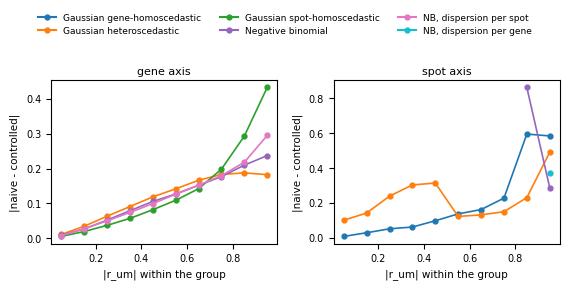

## FIGURE  fig_canal2_open_rum_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   Does the effect of the control grow with the uncertainty-mean coupling?
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION r_um is the Spearman correlation between the predicted uncertainty and the predicted
## CAPTION mean WITHIN a group: the quantity the control exists to remove. Each point is the
## CAPTION median absolute gap between the naive and the controlled correlation, over the groups
## CAPTION falling in one tenth of the |r_um| range.
## CAPTION A rising curve is the confounder behaving as the section claims. A flat one would
## CAPTION mean the control removes something unrelated to that coupling.

[printed twin -- median of |naive - controlled| per |r_um| bin]
  axis gene  Gaussian heteroscedastic                 (127,079 groups)  0.05:0.011(n=10488)  0.15:0.035(n=10668)  0.25:0.063(n=11018)  0.35:0.091(n=11668)  0.45:0.119(n=12323)  0.55:0.142(n=13397)  0.65

In [4]:
print("=" * 130)
print("r_um PER GROUP -- the uncertainty <-> predicted mean coupling, WITHIN the group")
print("  |r_um| ~ 1 on almost every group  ->  head mute on this axis, by construction")
print("=" * 130)
for axis in AXES:
    print(f"\n[axis {axis} | case {MAIN_CASE}]")
    print(f"  {'cohort':<22s} {'head':<40s} {'n':>9s} {'median':>9s} {'Q25':>8s} {'Q75':>8s} "
          f"{'% |r_um|>0.99':>14s}")
    for ds in DATASETS:
        for m in ALL_MODELS:
            d = groups(ds, m, axis, MAIN_CASE, "r_um")
            if d is None:
                continue
            v = d[f"r_um_{MAIN_CASE}"].to_numpy()
            print(f"  {DATASET_LABELS.get(ds, ds):<22s} {MODEL_LABELS.get(m, m):<40s} "
                  f"{len(v):>9,} {np.median(v):>+9.4f} {np.percentile(v, 25):>+8.3f} "
                  f"{np.percentile(v, 75):>+8.3f} {100 * np.mean(np.abs(v) > 0.99):>13.1f}%")

# ── the figure : the naive-controlled gap AGAINST r_um, one point per group ────────────────────
# If the confounder is indeed what the control removes, the gap must grow with |r_um|.
fig, axarr = plt.subplots(1, len(AXES), figsize=(2.9 * len(AXES), 2.9), squeeze=False)
printed = []
for k, axis in enumerate(AXES):
    ax = axarr[0, k]
    for m in MODELS:
        xs, ys = [], []
        for ds in DATASETS:
            d = groups(ds, m, axis, MAIN_CASE, "r_partial")
            if d is None:
                continue
            sub = d.dropna(subset=[f"r_uD_{MAIN_CASE}", f"r_um_{MAIN_CASE}"])
            if sub.empty:
                continue
            xs.append(np.abs(sub[f"r_um_{MAIN_CASE}"].to_numpy()))
            ys.append(np.abs(sub[f"r_uD_{MAIN_CASE}"].to_numpy()
                             - sub[f"r_partial_{MAIN_CASE}"].to_numpy()))
        if not xs:
            continue
        x, y = np.concatenate(xs), np.concatenate(ys)
        # Median of the gap per |r_um| bin : a scatter of 50k points cannot be read, ten
        # medians can.
        edges = np.linspace(0, 1, 11)
        idx = np.clip(np.digitize(x, edges) - 1, 0, 9)
        mid = 0.5 * (edges[:-1] + edges[1:])
        med = np.array([np.median(y[idx == b]) if np.any(idx == b) else np.nan for b in range(10)])
        ax.plot(mid, med, "o-", ms=3.5, lw=1.2, color=MODEL_COLORS.get(m, "0.4"),
                label=MODEL_LABELS.get(m, m))
        cnt = np.array([int((idx == b).sum()) for b in range(10)])
        printed.append(dict(axis=axis, model=m, mid=mid, med=med, n=len(x), cnt=cnt))
    ax.set_xlabel("|r_um| within the group", fontsize=7.5)
    ax.set_ylabel("|naive - controlled|", fontsize=7.5)
    ax.set_title(f"{axis} axis", fontsize=8, pad=4)
    ax.tick_params(labelsize=7)
handles = [Line2D([], [], marker="o", ls="-", color=MODEL_COLORS.get(m, "0.4"), ms=3.5,
                  label=MODEL_LABELS.get(m, m)) for m in MODELS
           if any(p["model"] == m for p in printed)]
fig.tight_layout(rect=(0, 0, 1, 0.84))
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3,
           frameon=False, fontsize=6.5)
fig_show(fig, FIGDIR / f"fig_canal2_open_rum_{MAIN_CASE}_{RUN_ID}_{CANAL2}",
         "Does the effect of the control grow with the uncertainty-mean coupling?",
         [f"Error definition: {CASE_FIG[MAIN_CASE]}.",
          "r_um is the Spearman correlation between the predicted uncertainty and the predicted",
          "mean WITHIN a group: the quantity the control exists to remove. Each point is the",
          "median absolute gap between the naive and the controlled correlation, over the groups",
          "falling in one tenth of the |r_um| range.",
          "A rising curve is the confounder behaving as the section claims. A flat one would",
          "mean the control removes something unrelated to that coupling."])

print("\n[printed twin -- median of |naive - controlled| per |r_um| bin]")
for p in printed:
    # the COUNT per bin, without which a huge gap over three groups reads as a
    # result : the x axis is a conditioning variable, not a population.
    cells = "  ".join(f"{x:.2f}:{v:.3f}(n={c})" if np.isfinite(v) else f"{x:.2f}:-"
                      for x, v, c in zip(p["mid"], p["med"], p["cnt"]))
    print(f"  axis {p['axis']:<5s} {MODEL_LABELS.get(p['model'], p['model']):<40s} "
          f"({p['n']:,} groups)  {cells}")

print("\n-- consistency check : r_um_lin_pos must EQUAL r_um_log_pos (same population, and")
print("   r_um does not depend on the error definition) --")
n_ok = n_bad = 0
for (ds, m), frame in list(PAIR.items()) + list(SPOT.items()):
    if "r_um_lin_pos" not in frame.columns or "r_um_log_pos" not in frame.columns:
        continue
    a, b = frame["r_um_lin_pos"].to_numpy(), frame["r_um_log_pos"].to_numpy()
    same = np.allclose(a, b, rtol=1e-9, atol=1e-12, equal_nan=True)
    n_ok, n_bad = n_ok + int(same), n_bad + int(not same)
    if not same:
        print(f"    (!) {ds}/{m} : max gap {np.nanmax(np.abs(a - b)):.3g} -- the two cases do not"
              f" read the same population, do not use this run.")
print(f"  {n_ok} file(s) conforming, {n_bad} failing.")

## 4. The three cases compared PER GROUP

This is the question the three cases exist to make possible, and it can only be asked here: the section 3 means can coincide while ranking different groups.

Two comparisons, each isolating one factor since the three cases differ by only one factor at a time:

- **`lin_pos` against `log_pos`** -- same population, different definitions → the gap is the effect of the error **DEFINITION**.
- **`lin_all` against `lin_pos`** -- same definition, different populations → the gap is the effect of the **POPULATION**, that is, of including the zeros.

We report the rank correlation between the per-group values and the median gap. A high correlation with a small gap means the choice does not matter; a low correlation means the two cases measure different things and the choice must be argued, not merely inherited.

In [5]:
from scipy.stats import spearmanr

PAIRS_OF_CASES = [("lin_pos", "log_pos", "DEFINITION (same population y>0)"),
                  ("lin_all", "lin_pos", "POPULATION (same definition |y-mu|)")]

rows = []
for (ds, m) in SUMM:
    for axis in AXES:
        frame = (PAIR if axis == "gene" else SPOT).get((ds, m))
        if frame is None:
            continue
        for ca, cb, _ in PAIRS_OF_CASES:
            xa, xb = f"r_partial_{ca}", f"r_partial_{cb}"
            na, nb = N_COL[ca], N_COL[cb]
            if any(c not in frame.columns for c in (xa, xb, na, nb)):
                continue
            # Both cases must be kept ON THE SAME group, otherwise we would compare two
            # different subsets and the gap would mix the comparison with the filter.
            d = frame[(frame[na] >= N_PLUS_MIN) & (frame[nb] >= N_PLUS_MIN)]
            d = d.dropna(subset=[xa, xb])
            if len(d) < 10:
                continue
            a, b = d[xa].to_numpy(), d[xb].to_numpy()
            rows.append(dict(dataset=ds, model=m, axis=axis, comp=f"{ca} vs {cb}", n=len(d),
                             rho=float(spearmanr(a, b).correlation),
                             med_a=float(np.median(a)), med_b=float(np.median(b)),
                             med_gap=float(np.median(b - a)),
                             pct_signe_oppose=float(100 * np.mean(a * b < 0))))
CMP = pd.DataFrame(rows)

print("=" * 134)
print("THE THREE CASES, COMPARED PER GROUP (CONTROLLED value)")
print("  high rho + small gap  ->  the choice of case changes nothing")
print("  low rho or many opposite signs  ->  the two cases measure different things")
print("=" * 134)
if CMP.empty:
    print("no comparable pair.")
else:
    for ca, cb, why in PAIRS_OF_CASES:
        comp = f"{ca} vs {cb}"
        for axis in AXES:
            sub = CMP[(CMP["comp"] == comp) & (CMP["axis"] == axis)]
            if sub.empty:
                continue
            print(f"\n[{comp} | axis {axis}]   the gap isolates : {why}")
            print(f"  {'cohort':<22s} {'head':<40s} {'n':>9s} {'rho':>8s} "
                  f"{'med ' + ca:>12s} {'med ' + cb:>12s} {'med gap':>10s} {'opp. sign':>11s}")
            for ds in DATASETS:
                for m in ALL_MODELS:
                    r = sub[(sub["dataset"] == ds) & (sub["model"] == m)]
                    if r.empty:
                        continue
                    r = r.iloc[0]
                    print(f"  {DATASET_LABELS.get(ds, ds):<22s} {MODEL_LABELS.get(m, m):<40s} "
                          f"{r['n']:>9,} {r['rho']:>+8.3f} {r['med_a']:>+12.4f} "
                          f"{r['med_b']:>+12.4f} {r['med_gap']:>+10.4f} "
                          f"{r['pct_signe_oppose']:>10.1f}%")
    print("\n-- summary, all runs pooled --")
    for comp in CMP["comp"].unique():
        for axis in AXES:
            s = CMP[(CMP["comp"] == comp) & (CMP["axis"] == axis)]
            if s.empty:
                continue
            print(f"  {comp:<22s} axis {axis:<5s} median rho {s['rho'].median():+.3f} "
                  f"[min {s['rho'].min():+.3f}, max {s['rho'].max():+.3f}]   "
                  f"signs opposes median {s['pct_signe_oppose'].median():.1f}%")

THE THREE CASES, COMPARED PER GROUP (CONTROLLED value)
  high rho + small gap  ->  the choice of case changes nothing
  low rho or many opposite signs  ->  the two cases measure different things

[lin_pos vs log_pos | axis gene]   the gap isolates : DEFINITION (same population y>0)
  cohort                 head                                             n      rho  med lin_pos  med log_pos    med gap   opp. sign
  Tumor Profiler         Gaussian heteroscedastic                    47,228   +0.901      +0.0822      +0.0601    -0.0120        9.1%
  Tumor Profiler         Gaussian spot-homoscedastic                 47,228   +0.873      +0.0954      +0.0716    -0.0103        8.9%
  Tumor Profiler         Negative binomial                           47,083   +0.946      +0.0702      +0.0577    -0.0064        8.3%
  Tumor Profiler         NB, dispersion per spot                     47,074   +0.943      +0.0538      +0.0422    -0.0060        8.9%
  Tumor Profiler         Negative binomial (raw

## 5. The spot axis, resolved by tissue type

The only section that reads the preprocessed adata. `spot_partial.parquet` carries `spot`, which **is** `adata_row` -- the positional row index into the merged adata, the project's canonical key. The join is therefore direct, and **all** spots are used, not a handful picked by hand.

**Which label to use** (settled decision, `src/data/load_and_preprocess.py`):

- **Primary view = the genuinely annotated spots** (`ground_truth` ≠ `UNASSIGNED`). On the TLS cohort, `UNASSIGNED` is a **deliberate** expert annotation category (ambiguous / mixed / transition), not a missing value: imputing there would amount to overriding an expert abstention.
- **Extension, always flagged as such = `ground_truth_knn_spatial_15`.** `spatial` is the only one of the three imputation spaces independent of both the model INPUT (`X_emb`) and its TARGET (log-CP10k); imputing with either would be circular here, since the tissue group would be defined with the very quantity whose per-group mean is then reported. Known weakness, to be stated: a purely geometric vote gets it wrong at region BOUNDARIES.

The imputed fraction is printed next to the primary view: agreement between the two is the defense against an imputation artifact.

10x_TuPro      77,338 spots   /cluster/work/grlab/projects/projects2026-msc-thesis-uncertainty-vst/clean_repo/results/10x_TuPro/_preprocessed/v5/r75/adata.h5ad
             UNASSIGNED : 0 (0.0 %)   imputed column present : False
             {'Tumor': np.int64(52240), 'Normal lymphoid tissue': np.int64(12938), 'Stroma': np.int64(9969), 'Blood and necrosis': np.int64(2173), 'Pigment': np.int64(18)}
TLS            19,437 spots   /cluster/work/grlab/projects/projects2026-msc-thesis-uncertainty-vst/clean_repo/results/TLS/_preprocessed/v5/r75/adata.h5ad
             UNASSIGNED : 10,110 (52.0 %)   imputed column present : True
             {'UNASSIGNED': np.int64(10110), 'NOR': np.int64(4410), 'TUM': np.int64(3705), 'TLS': np.int64(775), 'INFL': np.int64(404), 'LN': np.int64(33)}
LUNG_CANCER    68,659 spots   /cluster/work/grlab/projects/projects2026-msc-thesis-uncertainty-vst/clean_repo/results/LUNG_CANCER/_preprocessed/v5/r75/adata.h5ad

SPOT AXIS BY TISSUE TYPE -- GENUINE ANNOTATIONS (man

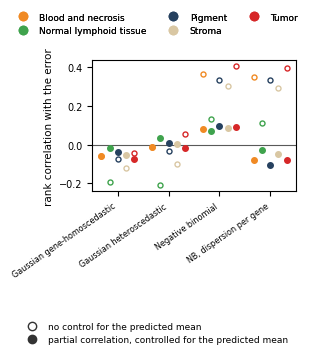

## FIGURE  fig_canal2_open_tissue_10x_TuPro_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   Tumor Profiler: spot axis resolved by tissue type, genuine expert annotations only
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One group per slide and spot: the correlation asks whether the predicted
## CAPTION uncertainty ranks the error across the genes of that spot. Spots are then grouped
## CAPTION by the tissue type of their expert annotation (color).
## CAPTION Hollow marker: no control. Filled marker: the partial correlation controlling for
## CAPTION the predicted mean. The vertical gap between the two IS the confounder.
## CAPTION UNASSIGNED spots are excluded: on this cohort that label is a deliberate expert
## CAPTION abstention, not a missing value, and imputing it would override it.
## CAPTION Spot counts per tissue are printed in the first table of this cell.


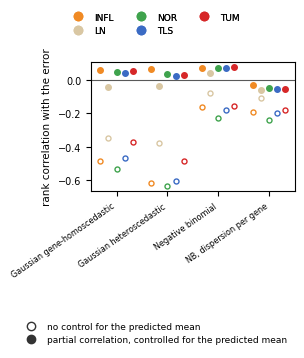

## FIGURE  fig_canal2_open_tissue_TLS_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITLE   Kidney/Lung with TLS: spot axis resolved by tissue type, genuine expert annotations only
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One group per slide and spot: the correlation asks whether the predicted
## CAPTION uncertainty ranks the error across the genes of that spot. Spots are then grouped
## CAPTION by the tissue type of their expert annotation (color).
## CAPTION Hollow marker: no control. Filled marker: the partial correlation controlling for
## CAPTION the predicted mean. The vertical gap between the two IS the confounder.
## CAPTION UNASSIGNED spots are excluded: on this cohort that label is a deliberate expert
## CAPTION abstention, not a missing value, and imputing it would override it.
## CAPTION Spot counts per tissue are printed in the first table of this cell.


In [6]:
import anndata as ad

IMPUTED_COL = "ground_truth_knn_spatial_15"


def adata_obs(ds):
    """obs of the merged adata, into which spot_partial['spot'] is a POSITIONAL row index.

    Two spellings of the radius segment coexist in the tree ('r75' and 'radius_75'), so we
    try both rather than making the user guess ; None if nothing is found, and the
    section se skipped properly."""
    for seg in (RADIUS, f"radius_{RADIUS.lstrip('r')}"):
        p = RESULTS / ds / "_preprocessed" / PREPROC_ID / seg / "adata.h5ad"
        if p.is_file():
            return ad.read_h5ad(p, backed="r").obs, p
    return None, None


OBS = {}
for ds in DATASETS:
    o, p = adata_obs(ds)
    if o is None:
        print(f"(!) {ds} : adata not found under _preprocessed/{PREPROC_ID}/ -- section skipped "
              f"for this cohort (check PREPROC_ID).")
        continue
    OBS[ds] = o
    gt = o["ground_truth"].astype(str) if "ground_truth" in o.columns else None
    n_un = int((gt == "UNASSIGNED").sum()) if gt is not None else 0
    print(f"{ds:<12s} {len(o):>8,} spots   {p}")
    if gt is not None:
        print(f"             UNASSIGNED : {n_un:,} ({100 * n_un / len(o):.1f} %)   "
              f"imputed column present : {IMPUTED_COL in o.columns}")
        print(f"             {dict(gt.value_counts())}")


def spot_by_tissue(ds, m, case, stat, label_col):
    """{tissue: (mean, n_spots)} for one run, joining spot_partial to adata.obs by adata_row."""
    d = groups(ds, m, "spot", case, stat)
    o = OBS.get(ds)
    if d is None or o is None or label_col not in o.columns:
        return {}
    lab = o[label_col].astype(str).to_numpy()[d["spot"].to_numpy()]
    v = d[f"{stat}_{case}"].to_numpy()
    keep = lab != "UNASSIGNED"      # never a group : it is an abstention, not a tissue
    lab, v = lab[keep], v[keep]
    return {t: (float(v[lab == t].mean()), int((lab == t).sum())) for t in sorted(set(lab))}


for label_col, tag in (("ground_truth", "GENUINE ANNOTATIONS (manual view)"),
                       (IMPUTED_COL, "IMPUTED spatial k=15 (EXTENSION, to be flagged as such)")):
    print("\n" + "=" * 134)
    print(f"SPOT AXIS BY TISSUE TYPE -- {tag}   case {MAIN_CASE}, CONTROLLED value")
    print("=" * 134)
    any_row = False
    for ds in DATASETS:
        o = OBS.get(ds)
        if o is None or label_col not in o.columns:
            continue
        # One single pass : the per-head result is reused by the table AND by the counts,
        # instead of being recomputed for each printed cell.
        by_model = {m: spot_by_tissue(ds, m, MAIN_CASE, "r_partial", label_col) for m in ALL_MODELS}
        by_model = {m: b for m, b in by_model.items() if b}
        if not by_model:
            continue
        any_row = True
        tissues = sorted({t for b in by_model.values() for t in b})
        print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
        print(f"  {'head':<40s} " + " ".join(f"{t[:14]:>15s}" for t in tissues))
        for m in ALL_MODELS:
            b = by_model.get(m)
            if not b:
                continue
            print(f"  {MODEL_LABELS.get(m, m):<40s} "
                  + " ".join((f"{b[t][0]:>+15.4f}" if t in b else f"{'-':>15s}") for t in tissues))
        # The spot counts : taken from the FIRST head that has any, not from ALL_MODELS[0],
        # which may be absent from the cohort and would then print silent zeros. They do not
        # depend on the head EXCEPT if a head is degenerate on the spot axis (it then has
        # no group), and such a head is already out of by_model.
        n0 = next(iter(by_model.values()))
        print(f"  {'(spots per tissue)':<40s} "
              + " ".join(f"{n0[t][1] if t in n0 else 0:>15,}" for t in tissues))
    if not any_row:
        print("  (column absent from every cohort)")

# ── the figure : one panel per cohort, one bar per (head, tissue), AUTHENTIC annotations ───────
# BOTH conditions, not only the controlled one : without the naive one the effect of the
# control is invisible, which is exactly what the section measures.
BY_TISSUE, BY_TISSUE_N = {}, {}
for ds in DATASETS:
    if ds in OBS and "ground_truth" in OBS[ds].columns:
        b = {m: spot_by_tissue(ds, m, MAIN_CASE, "r_partial", "ground_truth") for m in MODELS}
        b = {m: v for m, v in b.items() if v}
        if b:
            BY_TISSUE[ds] = b
            BY_TISSUE_N[ds] = {m: spot_by_tissue(ds, m, MAIN_CASE, "r_uD", "ground_truth")
                               for m in b}

if BY_TISSUE:
    # ONE figure PER COHORT. The tissue vocabularies differ from one cohort to the next
    # (TuPro : Tumor / Stroma / ... ; TLS : TUM / NOR / INFL / ...), so a shared legend
    # would mix two nomenclatures of which only half applies to each panel.
    for ds in [x for x in DATASETS if x in BY_TISSUE]:
        fig, ax = plt.subplots(figsize=(3.1, 2.9))
        by_model = BY_TISSUE[ds]
        live = [m for m in MODELS if m in by_model]
        tissues = sorted({t for b in by_model.values() for t in b})
        naive = BY_TISSUE_N.get(ds, {})
        w = 0.8 / max(len(tissues), 1)
        # Points and not bars : hollow = not controlled, filled = controlled, the same
        # convention as everywhere else. A bar could not show both conditions when they
        # change sign, which happens here.
        for ti, t in enumerate(tissues):
            xs = np.arange(len(live)) + ti * w - 0.4 + w / 2
            col = TISSUE_COLORS.get(t, "0.6")
            nv = [naive.get(m, {}).get(t, (np.nan, 0))[0] for m in live]
            pv = [by_model[m].get(t, (np.nan, 0))[0] for m in live]
            ax.plot(xs, nv, "o", ms=3.6, mfc="none", mec=col, mew=1.0, ls="", zorder=3)
            ax.plot(xs, pv, "o", ms=4.0, color=col, ls="", zorder=4)
        ax.axhline(0.0, color="0.35", lw=0.8)
        ax.set_xticks(range(len(live)))
        ax.set_xticklabels([MODEL_LABELS.get(m, m) for m in live], fontsize=5.8,
                           rotation=35, ha="right")
        ax.tick_params(axis="y", labelsize=7)
        ax.set_ylabel("rank correlation with the error", fontsize=7.5)
        handles = [Line2D([], [], marker="o", ls="", color=TISSUE_COLORS.get(t, "0.6"),
                          label=t) for t in tissues]
        cond = [Line2D([], [], marker="o", ls="", mfc="none", mec="#333333", mew=1.0,
                       label="no control for the predicted mean"),
                Line2D([], [], marker="o", ls="", color="#333333",
                       label="partial correlation, controlled for the predicted mean")]
        fig.tight_layout(rect=(0, 0, 1, 0.86))
        leg1 = fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
                          ncol=3, frameon=False, fontsize=6.5)
        fig.add_artist(leg1)
        fig.legend(handles=cond, loc="lower center", ncol=1, frameon=False, fontsize=6.5,
                   bbox_to_anchor=(0.5, -0.20))
        fig_show(fig, FIGDIR / f"fig_canal2_open_tissue_{ds}_{MAIN_CASE}_{RUN_ID}_{CANAL2}",
             f"{DATASET_LABELS.get(ds, ds)}: spot axis resolved by tissue type, genuine expert "
             f"annotations only",
             [f"Error definition: {CASE_FIG[MAIN_CASE]}.",
              "One group per slide and spot: the correlation asks whether the predicted",
              "uncertainty ranks the error across the genes of that spot. Spots are then grouped",
              "by the tissue type of their expert annotation (color).",
              "Hollow marker: no control. Filled marker: the partial correlation controlling for",
              "the predicted mean. The vertical gap between the two IS the confounder.",
              "UNASSIGNED spots are excluded: on this cohort that label is a deliberate expert",
              "abstention, not a missing value, and imputing it would override it.",
              "Spot counts per tissue are printed in the first table of this cell."])
else:
    print("\n(no cohort with a ground_truth column : no figure by tissue)")

## Two views this notebook does not produce

- **No pooled view over all genes.** A Spearman computed by mixing the genes mostly measures the expression gap between genes, not how informative the uncertainty is. The (gene, slide) or (slide, spot) grouping IS the measure; there is no simpler « global » version that stays honest.
- **No standardization of the columns.** Every quantity is on the model's native scale, as in the precompute. A figure putting Gaussians and counts on a shared error axis would require a conversion, that is exactly what the canal 2 rewrite removed.
- **No per-donor interval here.** The sections above open the mean along other dimensions (gene, tissue, `r_um`, case); the statistical uncertainty on the mean is section 3 of the main notebook, and mixing it into these breakdowns would give K too small for an interval.
- **The `_raw` heads appear on no shared figure.** Their error is measured against a target that carries the spot's library size: that is a different error axis, to be reported in its own table.